# 01 · How wrong can the Senate polls be, and what does that do to control?

> **Update 2026-10-30:** section 2's fade (−0.08 per point above the state's lean) and the 0.34 carry-over were estimated in-sample here. Tested out of sample in [notebook 04](04_model_selection.ipynb), the fade didn't predict misses and was dropped; the carry-over did, at 0.42. Holdout, my midterm model (Senate 73%), now uses only that; this notebook's numbers are its first version.

**Every published 2026 Senate forecast, from the Economist's 53% to Silver Bulletin's 76%, fits inside about 2 points of assumed polling bias.** With the error structure measured from 25 years of polls, the lean-adjusted polling averages give Democrats a 72% chance of control, and a center that also weights Split Ticket's model (models beat polls-only forecasts in 2018 and 2022) gives 71%, next to Polymarket's 67%; carrying over where the 2024 polls missed brings it to 66%. A 1.5-point polling miss either way moves the blend to roughly 52% or 85%, and the direction of the next miss is the thing history says can't be predicted.

1. The size and shape of polling misses, 1998–2022 (538's raw polls).
2. Do polls overstate candidates who run far ahead of their state's lean?
3. This year's Senate races from every source, side by side.
4. Simulated control under the error model, and the lean each published forecast implies.

The parameters and the literature behind them are in [the polling-error brief](../docs/polling-error-research.md).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from midterms import senate as S

pd.set_option("display.width", 180)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "axes.titlelocation": "left",
                     "axes.titleweight": "bold"})
BLUE, RED, INK = "#2a78d6", "#e34948", "#52514e"

## 1 · The size and shape of polling misses

For every Senate and governor race since 1998: the average of polls taken in the final three weeks, against the result. A positive miss means the Democrat beat their polls. 538's file, mirrored on GitHub after the site closed.

In [2]:
a = pd.read_csv("../data/history/race_poll_errors.csv")
even = a[a["cycle"] % 2 == 0]
sg = even[even["type_simple"].isin(["Sen-G", "Gov-G"])].copy()
nat = sg.groupby("cycle")["err"].mean()
gb = even[even["type_simple"] == "House-G-US"].set_index("cycle")["err"]
summary = pd.DataFrame({"Senate+governor races": sg.groupby("cycle").size(), "shared miss, D+": nat.round(1),
                        "generic ballot miss, D+": gb.round(1)})
summary["midterm"] = summary.index.isin([1998, 2002, 2006, 2010, 2014, 2018, 2022])
summary

,Senate+governor races,"shared miss, D+","generic ballot miss, D+",midterm
cycle,,,,
1998,53,3.5,-2.8,True
2000,41,2.0,-2.3,False
2002,63,-2.3,-5.3,True
2004,35,-1.9,-4.6,False
2006,59,0.9,-6.3,True
2008,43,0.6,1.9,False
2010,69,0.3,0.3,True
2012,37,2.9,0.8,False
2014,69,-3.4,-3.2,True


Text(0.01, -0.02, '538 raw polls, final 3 weeks. Midterm SD 2.3, all even years 3.0; no carryover in direction.')

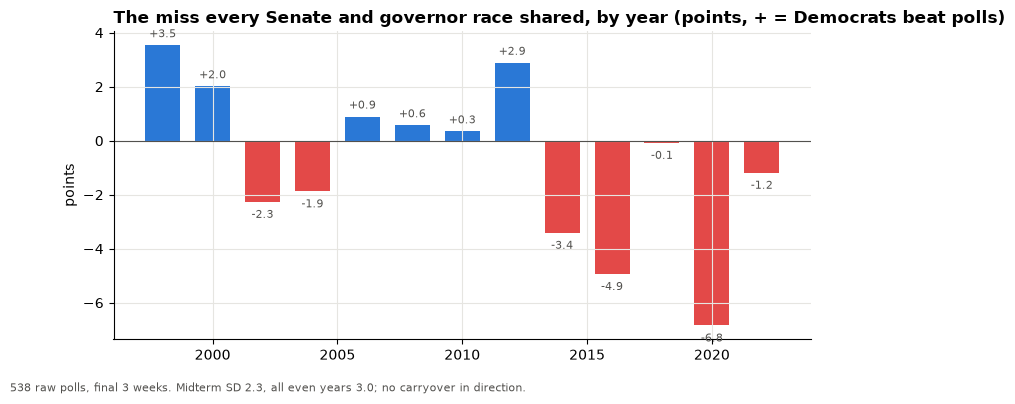

In [3]:
fig, ax = plt.subplots()
ax.bar(nat.index, nat.values, width=1.4, color=np.where(nat.values > 0, BLUE, RED))
ax.axhline(0, color=INK, lw=0.8)
for y, v in nat.items():
    ax.text(y, v + (0.3 if v > 0 else -0.6), f"{v:+.1f}", ha="center", fontsize=8, color=INK)
ax.set(title="The miss every Senate and governor race shared, by year (points, + = Democrats beat polls)",
       ylabel="points")
fig.text(0.01, -0.02, "538 raw polls, final 3 weeks. Midterm SD 2.3, all even years 3.0; no carryover in direction.",
         fontsize=8, color=INK)

In [4]:
sg["resid"] = sg["err"] - sg["cycle"].map(nat)
comp = sg[sg["poll"].abs() < 10].copy()
comp["polls"] = pd.cut(comp["n"], [0, 2, 5, 10, 1000], labels=["1–2", "3–5", "6–10", "11+"])
comp.groupby("polls", observed=True)["resid"].agg(races="size", race_specific_miss_sd="std").round(2)

,races,race_specific_miss_sd
polls,,
1–2,26,6.89
3–5,84,4.45
6–10,80,4.23
11+,95,3.44


Race-specific misses shrink with polling, but only so far: 3.4 points at 11+ polls. The brief's three-way split (national, state, race) puts a well-polled Senate race's total miss at ~4.9 points, matching what was measured; Split Ticket's probabilities imply 5.5.

## 2 · Running far ahead of the state's lean

Do polls overstate candidates who run well ahead of their state's presidential margin? Regress each race's miss (net of the year's shared miss) on how far the Democrat polled above the previous presidential margin.

In [5]:
pres = a[a["type_simple"] == "Pres-G"].groupby(["cycle", "location"])["actual"].first()
sg["lean"] = [pres.get((c - 4 if c % 4 == 0 else c - c % 4, s), np.nan) for c, s in zip(sg["cycle"], sg["location"])]
sg["gap"] = sg["poll"] - sg["lean"]
d = sg[(sg["poll"].abs() < 10) & sg["cycle"].isin([2002, 2006, 2010, 2014, 2018, 2022])].dropna(subset=["gap"])
X = np.c_[np.ones(len(d)), d["gap"]]
b, *_ = np.linalg.lstsq(X, d["resid"], rcond=None)
se = np.sqrt((d["resid"] - X @ b).var() / ((d["gap"] - d["gap"].mean()) ** 2).sum())
print(f"competitive midterm races: n={len(d)}, slope {b[1]:+.3f} per point (se {se:.3f})")
d.assign(bucket=pd.cut(d["gap"], [-60, 0, 5, 10, 15, 60])).groupby("bucket", observed=True)["resid"].agg(["size", "mean"]).round(2)

competitive midterm races: n=158, slope -0.082 per point (se 0.023)


,size,mean
bucket,,
"(-60, 0]",86,1.13
"(0, 5]",29,1.13
"(5, 10]",17,-0.84
"(10, 15]",9,-1.06
"(15, 60]",17,-3.25


Yes: about −0.08 points of miss per point a Democrat polls above the state's lean. This year's red-state Democrats (Kansas, Texas, Ohio, Alaska, Iowa, South Carolina, and Osborn in Nebraska) poll 14–20 points ahead of Trump's 2024 margins, so the adjusted average pulls each 1–1.7 points toward the Republican. This is most of why the models sit to the right of the polls in those states.

## 3 · This year's Senate races from every source

In [6]:
df = S.races()
show = ["state", "held_by", "lean_2024", "poll_margin", "poll_adj", "n_polls_30d", "st_margin", "st_p_d", "pm_p_d"]
df[df["st_p_d"].between(0.03, 0.97) | df["pm_p_d"].between(0.03, 0.97)][show].round(2)

,state,held_by,lean_2024,poll_margin,poll_adj,n_polls_30d,st_margin,st_p_d,pm_p_d
9,NC,R,-3.21,10.19,9.09,8,8.8,0.96,0.97
10,GA,D,-2.19,10.33,9.30,4,8.5,0.95,0.97
11,NH,D,2.78,7.23,6.87,5,8.2,0.91,0.90
12,MN,D,4.24,6.48,6.30,9,5.8,0.84,0.91
13,MI,D,-1.42,3.68,3.26,14,3.2,0.73,0.73
14,OH,R,-11.21,3.07,1.90,13,3.0,0.71,0.68
15,TX,R,-13.68,2.95,1.59,21,2.4,0.70,0.70
16,AK,R,-13.13,3.70,2.32,6,2.0,0.66,0.71
17,ME,R,6.94,2.49,2.85,13,1.5,0.61,0.65
18,IA,R,-13.21,0.85,-0.30,13,-0.2,0.49,0.47


## 4 · Control under the error model

In [7]:
rows = []
for label, m in [("first cut (national SD 2.3)", S.ErrorModel.first_cut()), ("main", S.ErrorModel()),
                 ("main, polls overstate D by 1.5", S.ErrorModel(nat_mean=-1.5)),
                 ("main, polls understate D by 1.5", S.ErrorModel(nat_mean=1.5))]:
    for center in ["poll_margin", "poll_adj", "st_margin"]:
        _, s = S.simulate(df, center=center, model=m, n=80_000)
        rows.append(dict(spec=label, center=center, p=s["p_d_control"]))
pd.DataFrame(rows).pivot(index="spec", columns="center", values="p").round(3)

center,poll_adj,poll_margin,st_margin
spec,,,
first cut (national SD 2.3),0.747,0.843,0.716
main,0.721,0.816,0.690
"main, polls overstate D by 1.5",0.534,0.656,0.500
"main, polls understate D by 1.5",0.859,0.914,0.837


In [8]:
out, s = S.simulate(df, center="poll_adj", n=100_000)
print(f"main: P(D control) {s['p_d_control']:.1%}, D seats mean {s['mean_d_seats']:.1f}, "
      f"80% range {s['seats_p10']:.0f}–{s['seats_p90']:.0f} (D need 51; {s['d_not_up']} D seats not up)")
out[out["sim_p_d"].between(0.03, 0.97)][["state", "poll_adj", "race_sd", "sim_p_d", "st_p_d", "pm_p_d"]].round(2)

main: P(D control) 72.5%, D seats mean 52.1, 80% range 48–56 (D need 51; 34 D seats not up)


,state,poll_adj,race_sd,sim_p_d,st_p_d,pm_p_d
9,NC,9.09,3.82,0.97,0.96,0.97
10,GA,9.30,4.45,0.96,0.95,0.97
11,NH,6.87,3.82,0.93,0.91,0.90
12,MN,6.30,3.82,0.91,0.84,0.91
13,MI,3.26,3.82,0.77,0.73,0.73
14,OH,1.90,3.82,0.66,0.71,0.68
15,TX,1.59,3.82,0.64,0.70,0.70
16,AK,2.32,3.82,0.70,0.66,0.71
17,ME,2.85,3.82,0.74,0.61,0.65
18,IA,-0.30,3.82,0.47,0.49,0.47


### The polling lean each forecast implies

Hold the error model fixed and find the shift in the national miss that reproduces each published Senate number.

In [9]:
def p_at(lean):
    return S.simulate(df, center="poll_adj", model=S.ErrorModel(nat_mean=lean), n=60_000, seed=1)[1]["p_d_control"]


published = {"Economist": 0.53, "DDHQ (reported)": 0.60, "VoteHub": 0.60, "Split Ticket": 0.61, "Kalshi / Polymarket": 0.67,
             "Strength In Numbers (Oct 1)": 0.73, "Silver Bulletin": 0.764}
implied = {}
for name, target in published.items():
    lo, hi = -4.0, 4.0
    for _ in range(14):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if p_at(mid) < target else (lo, mid)
    implied[name] = (lo + hi) / 2
imp = pd.DataFrame({"P(D Senate)": published, "implied lean, pts (+ = polls understate D)": implied}).round(2)
imp

,P(D Senate),"implied lean, pts (+ = polls understate D)"
Economist,0.53,-1.54
DDHQ (reported),0.60,-1.02
VoteHub,0.60,-1.02
Split Ticket,0.61,-0.94
Strength In Numbers (Oct 1),0.73,0.04
Silver Bulletin,0.76,0.37


Text(0.01, -0.02, 'Lean-adjusted Silver Bulletin averages; error model from docs/polling-error-research.md; 60k draws.')

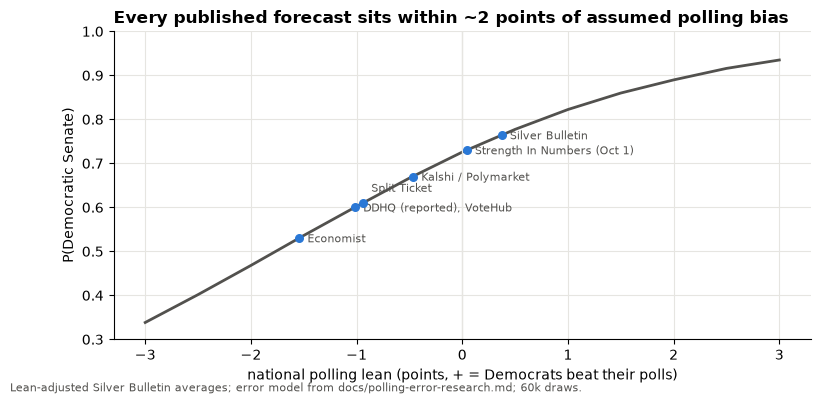

In [10]:
leans = np.linspace(-3, 3, 13)
curve = [p_at(x) for x in leans]
fig, ax = plt.subplots()
ax.plot(leans, curve, color=INK, lw=2)
labels = {}  # sources with the same published number share one label
for name, x in implied.items():
    labels.setdefault(published[name], (x, []))[1].append(name)
for i, (pv, (x, names)) in enumerate(sorted(labels.items())):
    ax.scatter([x], [pv], s=30, color=BLUE, zorder=3)
    dy = 8 if names == ["Split Ticket"] else -3  # Split Ticket sits just above DDHQ/VoteHub
    ax.annotate(", ".join(names), (x, pv), textcoords="offset points", xytext=(6, dy), fontsize=8, color=INK)
ax.axvline(0, color="#e6e5e1", lw=1)
ax.set(xlabel="national polling lean (points, + = Democrats beat their polls)", ylabel="P(Democratic Senate)",
       title="Every published forecast sits within ~2 points of assumed polling bias", ylim=(0.3, 1))
fig.text(0.01, -0.02, "Lean-adjusted Silver Bulletin averages; error model from docs/polling-error-research.md; 60k draws.",
         fontsize=8, color=INK)

## 5 · Whose number to lean on

Track record, 2018 and 2022 (538's archived forecasts, PredictIt 2018 and Polymarket 2022 against certified results): the forecast that blended polls with fundamentals and expert ratings (538 "Deluxe") scored best in both cycles; the markets did about as well as a good model in 2018 (PredictIt) and worse than every 538 version in 2022 (Polymarket, only 32 thinly traded races); the polls-only version had the largest margin errors (4.6 vs 7.2 points of mean absolute error in 2018). Every source missed in the same direction in 2022, so averaging them doesn't cancel a shared miss.

So the center below averages the lean-adjusted polls with Split Ticket's margins, and keeps the error model unchanged. (DDHQ's margins were in this blend until 2026-10-29; The Hill's robots.txt disallows AI crawlers, so its data is no longer collected or used. Its published toplines above are as reported.)

In [11]:
rows = []
for lean in (-1.5, 0.0, 1.5):
    _, s = S.simulate(df, center="blend", model=S.ErrorModel(nat_mean=lean), n=100_000)
    rows.append({"polling lean (+ = D beat polls)": lean, "P(D Senate)": s["p_d_control"],
                 "D seats, mean": s["mean_d_seats"], "80% range": f"{s['seats_p10']:.0f}–{s['seats_p90']:.0f}"})
pd.DataFrame(rows).round(3)

,polling lean (+ = D beat polls),P(D Senate),"D seats, mean",80% range
0,-1.5,0.516,50.575,47–54
1,0.0,0.708,51.910,48–55
2,1.5,0.849,53.176,50–56


## 6 · Where the 2024 polls missed, carried into 2026

A state's presidential-year polling miss (relative to that year's national miss) has carried into the next midterm: slope 0.34 (se 0.08) across 2000–2022, 0.54 (se 0.11) for 2016→18 and 2020→22. The 2024 averages come from Wikipedia's statewide polling tables (polls ending Oct 15 – Nov 5), against the certified 2024 results.

In [12]:
from midterms import pres2024 as P

miss = pd.read_csv("../data/history/pres2024_state_miss.csv").set_index("state")
print(f"2024: polls overstated Harris by {-miss['miss'].mean():.1f} points on average across {len(miss)} states")
df[df["st_p_d"].between(0.03, 0.97)][["state", "blend", "miss24_rel", "n_polls_2024"]].round(2)

2024: polls overstated Harris by 3.1 points on average across 35 states


,state,blend,miss24_rel,n_polls_2024
9,NC,8.95,1.13,4.0
10,GA,8.90,2.10,4.0
11,NH,7.53,-0.40,4.0
12,MN,6.05,1.66,4.0
13,MI,3.23,0.62,4.0
14,OH,2.45,-0.00,3.0
15,TX,1.99,-3.04,4.0
16,AK,2.16,0.01,1.0
17,ME,2.18,NaN,NaN
18,IA,-0.25,-5.52,2.0


In [13]:
rows = []
for beta, label in [(0.0, "no carry-over"), (P.PERSISTENCE, "0.34 (all pairs)"), (P.PERSISTENCE_RECENT, "0.54 (2016→22 pairs)")]:
    d = df.assign(c=S.with_carryover(df, beta))
    _, s = S.simulate(d, center="c", n=100_000)
    rows.append({"carry-over": label, "P(D Senate)": s["p_d_control"], "D seats, mean": s["mean_d_seats"]})
pd.DataFrame(rows).round(3)

,carry-over,P(D Senate),"D seats, mean"
0,no carry-over,0.708,51.910
1,0.34 (all pairs),0.663,51.560
2,0.54 (2016→22 pairs),0.638,51.381


The carry-over points toward Republicans: the 2024 polls overstated Harris by more than the national average in Iowa (−5.5 relative), Kansas (−4.6) and Texas (−3.0), all close Senate races this year. Iowa's figure rests on 2 polls in the final window (one of them the Selzer Harris+3 outlier), so it's the noisiest input here.